# 8장. 작은 데이터 분석 프로젝트 완성하기

이 노트북은 **질문 → 원본 데이터 점검 → 전처리 → PK/FK 검증 → 안전한 병합 → completed 범위 집계 → 총합 대조 → 시각화 → 보고서 → 최종 Validation**을 하나의 재현 가능한 프로젝트로 연결합니다.

> 코드가 끝까지 실행되었다는 사실만으로 프로젝트가 검증된 것은 아닙니다. 같은 의미의 숫자와 공개 산출물이 정해 둔 기준을 함께 통과해야 합니다.


## 학습 목표

- 원본 데이터를 보존하며 전처리합니다.
- 주요 PK의 결측·중복과 FK 미매칭을 확인합니다.
- `validate`와 `indicator` 관점으로 병합 결과를 검증합니다.
- `line_total = quantity × unit_price`를 다시 확인합니다.
- 금액성 분석은 `order_status == "completed"` 범위를 사용합니다.
- 카테고리·월·고객 금액 합계를 같은 source total과 대조합니다.
- 날짜 오류로 월별 금액이 누락되지 않는지 확인합니다.
- 공개 고객 결과에서 원본 고객 ID와 직접 식별정보를 제거합니다.
- 결과 CSV, 그래프, Markdown 보고서와 PASS/FAIL Evidence를 저장합니다.
- 전체 파이프라인을 다시 실행해 재현성을 확인합니다.


## 프로젝트 질문과 계산 기준 (실행 전 정의)
### 분석 질문
1. 카테고리별 completed 주문 금액과 비중은 어떻게 다른가?
2. 월별 completed 주문 금액과 고유 주문 수는 어떻게 변하는가?
3. completed 구매 금액 상위 익명 고객은 구매 횟수와 주문당 금액에서 어떤 특징을 보이는가?
### 분석 범위
공식 공개 저장소의 가상 쇼핑몰 원본 4개 파일을 사용한다. 전체 주문의 관측 날짜는 2025-07-09~2026-07-08이다. 금액·고객 분석은 completed 주문만 포함하고, 주문 상태 분포만 전체 orders를 사용한다. 금액은 원 단위이며 회계상 순매출이나 이익을 뜻하지 않는다.
### 사용할 데이터와 지표
customers, products, orders, order_items를 사용한다. 금액 합계, 금액 비중, 고유 주문 수, 고객별 주문당 평균 금액을 계산한다. 주문 수는 상세 행 수가 아니라 order_id.nunique()이다.
### 계산 기준
- `order_status == "completed"`: 적용함(184개 주문, 474개 상세 행).
- `line_total = quantity × unit_price`: 764개 상세 행에서 검증, 불일치 0건.
### 완료 기준
PK 결측·중복 0, FK 미매칭 0, 병합 행 수 보존, 계산 불일치 0, 날짜 오류 0, 네 금액 총합 일치, 공개 고객 결과 금지 컬럼 없음, 최종 Validation 8개 PASS 및 별도 재실행 결과 일치를 완료 기준으로 삼았다.

## 1. 프로젝트 루트와 출력 폴더 설정

VS Code에서 현재 작업 폴더가 프로젝트 루트 또는 `notebooks`일 수 있으므로 상위 폴더를 탐색합니다.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd

def find_project_root(start):
    for candidate in [start, start / "chapter08", *start.parents]:
        if (candidate / "source_manifest.json").exists() and (candidate / "src/midterm_project.py").exists():
            return candidate.resolve()
    raise FileNotFoundError("chapter08 폴더에서 Notebook을 열고 실행하세요.")

PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DIR = PROJECT_ROOT / "data/raw"
PROCESSED_DIR = PROJECT_ROOT / "data/processed"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"
for path in [PROCESSED_DIR, REPORT_DIR, FIGURE_DIR]:
    path.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_ROOT))
print("Python:", sys.executable)
print("Chapter root:", PROJECT_ROOT)
print("Source: official synthetic sample (source_manifest.json)")

Python: C:\Users\신윤철\AppData\Local\Python\pythoncore-3.14-64\python.exe
Chapter root: C:\Users\신윤철\Documents\llm-data-analysis-study\chapter08
Source: official synthetic sample (source_manifest.json)


## 2. 프로젝트 함수 불러오기

Notebook과 일괄 실행 스크립트가 같은 `src.midterm_project` 함수를 사용하도록 하여 계산 기준이 어긋나는 문제를 줄입니다.


In [2]:
from src.data_loader import load_sales_data
from src.preprocessing import (
    compare_shapes,
    preprocess_sales_data,
    save_processed_data,
    validate_relationships,
)
from src.midterm_project import (
    FORBIDDEN_CUSTOMER_COLUMNS,
    build_analysis_tables,
    build_interpretation_notes,
    build_key_duplicate_checks,
    build_midterm_report,
    build_project_validation,
    create_project_figures,
    run_midterm_project,
    save_project_tables,
    summarize_datasets,
)


## 3. 원본 데이터 확인

프로젝트는 `data/raw`의 원본 4개 파일에서 시작합니다. 파일이 없다면 프로젝트 루트에서 `python scripts/generate_sample_data.py`를 먼저 실행합니다.


In [3]:
raw_data = load_sales_data(RAW_DIR)

dataset_summary = summarize_datasets(raw_data)
display(dataset_summary)

for name, df in raw_data.items():
    print(f"\n===== {name} =====")
    print("shape:", df.shape)
    print("columns:", df.columns.tolist())
    print("missing values:", int(df.isna().sum().sum()))
    print("duplicated rows:", int(df.duplicated().sum()))


,dataset,rows,columns,missing_values,duplicated_rows
0,customers,150,6,0,0
1,products,100,4,0,0
2,orders,300,5,0,0
3,order_items,764,5,0,0



===== customers =====
shape: (150, 6)
columns: ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']
missing values: 0
duplicated rows: 0

===== products =====
shape: (100, 4)
columns: ['product_id', 'product_name', 'category', 'price']
missing values: 0
duplicated rows: 0

===== orders =====
shape: (300, 5)
columns: ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status']
missing values: 0
duplicated rows: 0

===== order_items =====
shape: (764, 5)
columns: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price']
missing values: 0
duplicated rows: 0


## 4. 원본을 보존하며 전처리

`preprocess_sales_data()`는 원본 DataFrame을 직접 수정하지 않고 전처리된 복사본을 반환합니다. 전처리 전후 행 수가 달라졌다면 그 이유를 설명할 수 있어야 합니다.


In [4]:
processed_data = preprocess_sales_data(raw_data)
processed_paths = save_processed_data(processed_data, PROCESSED_DIR)
preprocessing_comparison = compare_shapes(raw_data, processed_data)
print("원본 행/열·결측·중복 요약")
display(dataset_summary)
print("전처리 전후 비교")
display(preprocessing_comparison)
print("원본 4종: 결측/완전중복 0, 행 수 변동 0; 주문 월/요일·line_total 파생 열 추가")

원본 행/열·결측·중복 요약


,dataset,rows,columns,missing_values,duplicated_rows
0,customers,150,6,0,0
1,products,100,4,0,0
2,orders,300,5,0,0
3,order_items,764,5,0,0


전처리 전후 비교


,dataset,rows_raw,columns_raw,rows_processed,columns_processed
0,customers,150,6,150,6
1,order_items,764,5,764,6
2,orders,300,5,300,7
3,products,100,4,100,4


원본 4종: 결측/완전중복 0, 행 수 변동 0; 주문 월/요일·line_total 파생 열 추가


### 전처리 결과 관찰 및 판단
4개 파일 모두 결측·완전 중복이 0이며 행 수는 그대로다. 날짜·숫자형과 파생 열만 정리했다. 공식 원본 SHA-256을 보존했고 이후 검증에서 다시 대조한다. 행을 줄이지 않았다고 전처리가 누락된 것은 아니다.

## 5. PK와 FK를 먼저 검증

전체 행 중복과 PK 중복은 다릅니다. 고객·상품·주문·주문 상세의 PK는 **결측 0, 중복 0**이어야 합니다. FK는 부모 테이블에 없는 참조 ID가 0건이어야 합니다.


In [5]:
key_duplicate_checks = build_key_duplicate_checks(processed_data)
relationship_checks = validate_relationships(processed_data).copy()

if not relationship_checks.empty:
    relationship_checks["status"] = (
        relationship_checks["invalid_count"]
        .eq(0)
        .map({True: "PASS", False: "FAIL"})
    )

display(key_duplicate_checks)
display(relationship_checks)

assert key_duplicate_checks["status"].eq("PASS").all(), "PK Validation 실패"
assert (
    not relationship_checks.empty
    and relationship_checks["invalid_count"].eq(0).all()
), "FK Validation 실패"

print("PK/FK Gate: PASS")


,dataset,key,missing_count,duplicate_count,status,detail
0,customers,customer_id,0,0,PASS,
1,products,product_id,0,0,PASS,
2,orders,order_id,0,0,PASS,
3,order_items,order_item_id,0,0,PASS,


,check,invalid_count,status
0,orders.customer_id exists in customers.custome...,0,PASS
1,order_items.order_id exists in orders.order_id,0,PASS
2,order_items.product_id exists in products.prod...,0,PASS


PK/FK Gate: PASS


## 6. 안전한 병합과 계산 관계 검증

`build_analysis_tables()`는 다음을 한 번에 준비합니다.

- 주문 상세 → 주문: `many_to_one`
- 주문 상세 → 상품: `many_to_one`
- 고객 집계 → 고객: `one_to_one`
- 병합 전후 행 수와 미매칭 확인
- `line_total = quantity × unit_price` 확인
- completed 주문 범위 확정
- 날짜 오류 확인


In [6]:
analysis_tables = build_analysis_tables(processed_data)

display(analysis_tables["merge_checks"])
display(analysis_tables["line_total_check"])
display(analysis_tables["date_checks"])
display(analysis_tables["amount_scope_summary"])

assert analysis_tables["merge_checks"]["status"].eq("PASS").all()
assert analysis_tables["line_total_check"]["status"].eq("PASS").all()

print("병합 / line_total Gate: PASS")


,merge,validate,before_rows,after_rows,row_count_preserved,unmatched_count,status
0,order_id → orders,many_to_one,764,764,True,0,PASS
1,product_id → products,many_to_one,474,474,True,0,PASS
2,customer_id → customers,one_to_one,100,100,True,0,PASS


,check,source,row_count,mismatch_count,status
0,line_total = quantity × unit_price,existing,764,0,PASS


,check,invalid_count,affected_amount,status
0,completed rows with invalid order_date,0,0.0,PASS


,scope,amount,detail_rows
0,all_order_items,255610000.0,764
1,completed_order_items,148990000.0,474
2,excluded_non_completed,106620000.0,290


병합 / line_total Gate: PASS


## 7. 핵심 분석 결과 확인

세 금액성 결과는 같은 `completed_order_sales`에서 출발합니다. 주문 상태 분포만 전체 주문을 사용합니다.


In [7]:
category_sales = analysis_tables["category_sales"]
monthly_sales = analysis_tables["monthly_sales"]
customer_sales_internal = analysis_tables["customer_sales"]
customer_sales_public = analysis_tables["customer_sales_public"]
order_status_summary = analysis_tables["order_status_summary"]

display(category_sales)
display(monthly_sales)
display(customer_sales_public.head(10))
display(order_status_summary)

print("내부 고객 결과 컬럼:", customer_sales_internal.columns.tolist())
print("공개 고객 결과 컬럼:", customer_sales_public.columns.tolist())


,category,total_quantity,total_sales,sales_ratio
0,스포츠,295,31743000,21.31
1,전자기기,259,26400000,17.72
2,생활용품,272,23915000,16.05
3,뷰티,223,23383000,15.69
4,식품,133,16573000,11.12
5,도서,149,16389000,11.00
6,패션,111,10587000,7.11


,order_month,total_sales,order_count,avg_order_value
0,2025-07,5869000,8,733625.0
1,2025-08,15621000,18,867833.0
2,2025-09,10190000,13,783846.0
3,2025-10,25766000,26,991000.0
4,2025-11,8812000,12,734333.0
5,2025-12,11501000,14,821500.0
6,2026-01,17423000,22,791955.0
7,2026-02,9749000,17,573471.0
8,2026-03,13429000,14,959214.0
9,2026-04,17553000,23,763174.0


,customer_label,city,order_count,total_sales,avg_order_value
0,Customer 01,성남,5,4100000,820000.0
1,Customer 02,고양,4,3996000,999000.0
2,Customer 03,수원,4,3880000,970000.0
3,Customer 04,서울,5,3590000,718000.0
4,Customer 05,서울,4,3523000,880750.0
5,Customer 06,인천,2,3191000,1595500.0
6,Customer 07,성남,2,3178000,1589000.0
7,Customer 08,광주,3,3153000,1051000.0
8,Customer 09,서울,4,3093000,773250.0
9,Customer 10,부산,2,2990000,1495000.0


,order_status,order_count,order_ratio
0,completed,184,61.33
1,cancelled,64,21.33
2,refunded,52,17.33


내부 고객 결과 컬럼: ['customer_id', 'customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
공개 고객 결과 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']


### EDA 관찰·판단·의미·한계
- 카테고리: 스포츠 31,743,000원(21.31%)이 가장 높아 수량·단가 분해 후보로 삼는다. 선호·마진 우위는 알 수 없다.
- 월별: 2025-10 25,766,000원·26개 주문이 최고다. 마지막 2026-07은 7월 8일까지만 관측되어 감소 추세로 단정할 수 없다.
- 고객: Customer 01은 4,100,000원·5회 구매다. 고액·반복 구매를 구분할 가치가 있으나 충성도·미래 구매를 뜻하지 않는다.
- 금액성 결과는 184개 완료 주문의 상세 474개이며 전체 상세 764개와 구분한다.

## 8. 같은 의미의 금액 총합을 교차 검증

같은 completed 범위에서 만든 결과라면 다음 네 금액이 일치해야 합니다.

```text
completed source total
= category total
= monthly total
= customer total
```

날짜 오류가 있으면 월별 합계가 source total보다 작아질 수 있으므로 별도 Gate로 확인합니다.


In [8]:
total_consistency = analysis_tables["total_consistency_check"]
display(total_consistency)

assert total_consistency["matches_completed"].all(), "Total consistency Gate 실패"
assert analysis_tables["date_checks"]["status"].eq("PASS").all(), "날짜 Gate 실패"

print("Total consistency / Date Gate: PASS")


,source,amount,difference_from_completed,matches_completed,status
0,completed_source,148990000.0,0.0,True,PASS
1,category,148990000.0,0.0,True,PASS
2,monthly,148990000.0,0.0,True,PASS
3,customer,148990000.0,0.0,True,PASS


Total consistency / Date Gate: PASS


### 총합 관찰과 판단
네 합계가 모두 148,990,000원이며 날짜 오류와 영향 금액은 0이다. 합계가 맞더라도 개별 그룹 배분은 틀릴 수 있어 별도 재계산으로 카테고리·월별 각 값을 대조한다.

## 9. 공개 고객 결과의 개인정보를 확인

내부 계산에는 `customer_id`가 필요할 수 있지만 공개 CSV·그래프·보고서에는 원본 고객 ID와 직접 식별정보를 포함하지 않습니다. 공개 라벨은 `Customer 01` 같은 순위 기반 라벨을 사용합니다.


In [9]:
forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(customer_sales_public.columns)
)
print("공개 결과 금지 컬럼:", forbidden)

assert not forbidden, "Privacy Gate 실패"
assert "customer_id" not in customer_sales_public.columns
print("Privacy Gate: PASS")


공개 결과 금지 컬럼: []
Privacy Gate: PASS


## 10. 최종 PASS/FAIL Validation

지금까지의 핵심 Gate를 하나의 표로 정리합니다. 하나라도 FAIL이면 결과를 제출 가능한 완료 상태로 보지 않습니다.


In [10]:
project_validation = build_project_validation(
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
)
display(project_validation)

assert project_validation["status"].eq("PASS").all(), "최종 Validation 실패"
print("Project Validation: PASS")


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


Project Validation: PASS


## 11. 해석 메모와 결과 CSV 저장

관찰, 주의점, 다음 질문을 분리합니다. 저장되는 `ch08_customer_sales.csv`는 공개용 컬럼만 포함합니다.


In [11]:
interpretation_notes = build_interpretation_notes()
display(interpretation_notes)

saved_tables = save_project_tables(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
    REPORT_DIR,
)

for path in saved_tables:
    print(path.name, path.exists(), path.stat().st_size)


,analysis,observation,caution,next_question
0,카테고리별 completed 주문 기준 금액,completed 주문 기준 금액 비중이 높은 카테고리를 확인할 수 있습니다.,금액이 높은 이유가 판매 수량인지 단가인지 구분해야 합니다.,카테고리별 평균 판매 단가는 어떻게 다른가?
1,월별 completed 주문 기준 금액,시간에 따른 completed 주문 기준 금액의 증가와 감소를 확인할 수 있습니다.,프로모션이나 계절성이 원인이라고 단정할 수 없습니다.,주문 수와 평균 주문 금액 중 무엇이 변했는가?
2,고객별 completed 주문 구매 금액,completed 주문 기준 구매 금액이 높은 고객군을 확인할 수 있습니다.,일회성 고액 구매와 반복 구매를 구분해야 합니다.,최근 구매일과 구매 빈도는 어떻게 다른가?
3,주문 상태별 주문 수,"완료, 취소, 환불 주문의 분포를 확인할 수 있습니다.",주문 상태의 정의와 처리 기준을 확인해야 합니다.,취소율과 환불률은 월별로 달라지는가?


ch08_dataset_summary.csv True 138
ch08_preprocessing_comparison.csv True 156
ch08_key_duplicate_checks.csv True 188
ch08_relationship_checks.csv True 206
ch08_merge_checks.csv True 253
ch08_line_total_check.csv True 106
ch08_date_checks.csv True 98
ch08_amount_scope_summary.csv True 141
ch08_total_consistency_check.csv True 220
ch08_project_validation.csv True 394
ch08_category_sales.csv True 254
ch08_monthly_sales.csv True 438
ch08_customer_sales.csv True 3960
ch08_order_status_summary.csv True 101
ch08_interpretation_notes.csv True 1089


## 12. 저장된 공개 고객 CSV를 다시 검사

메모리의 DataFrame만 보지 않고 실제 저장된 CSV를 다시 읽어 개인정보 컬럼이 남지 않았는지 확인합니다.


In [12]:
saved_customer = pd.read_csv(REPORT_DIR / "ch08_customer_sales.csv")

saved_forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(saved_customer.columns)
)
print("저장 CSV 컬럼:", saved_customer.columns.tolist())
print("금지 컬럼:", saved_forbidden)

assert not saved_forbidden
print("저장된 고객 CSV Privacy Gate: PASS")


저장 CSV 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
금지 컬럼: []
저장된 고객 CSV Privacy Gate: PASS


## 13. 검증된 집계표에서 그래프 생성

그래프는 새로운 계산 범위를 만드는 단계가 아니라 검증된 숫자를 전달하는 단계입니다.


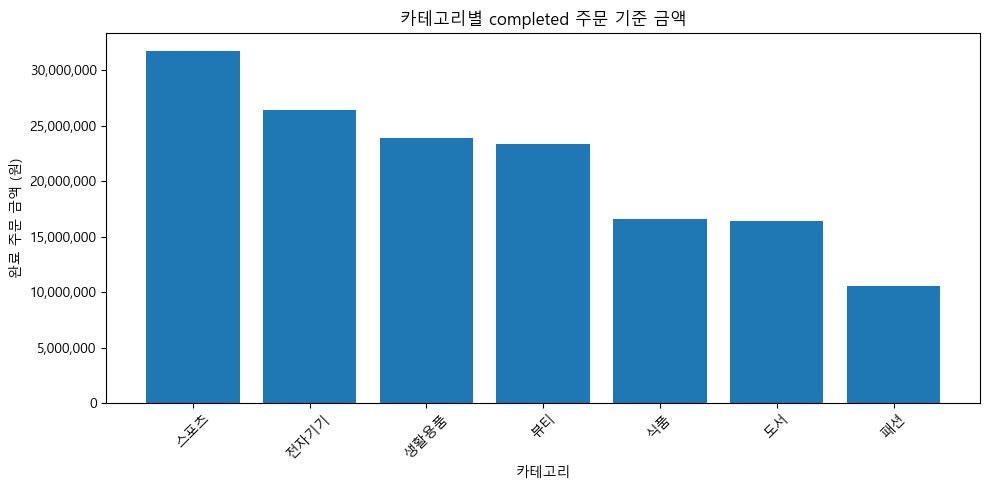

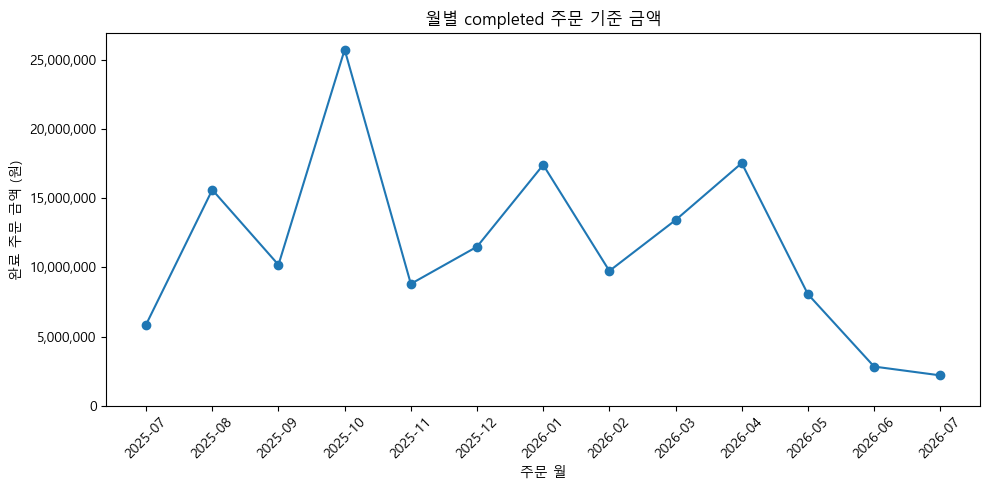

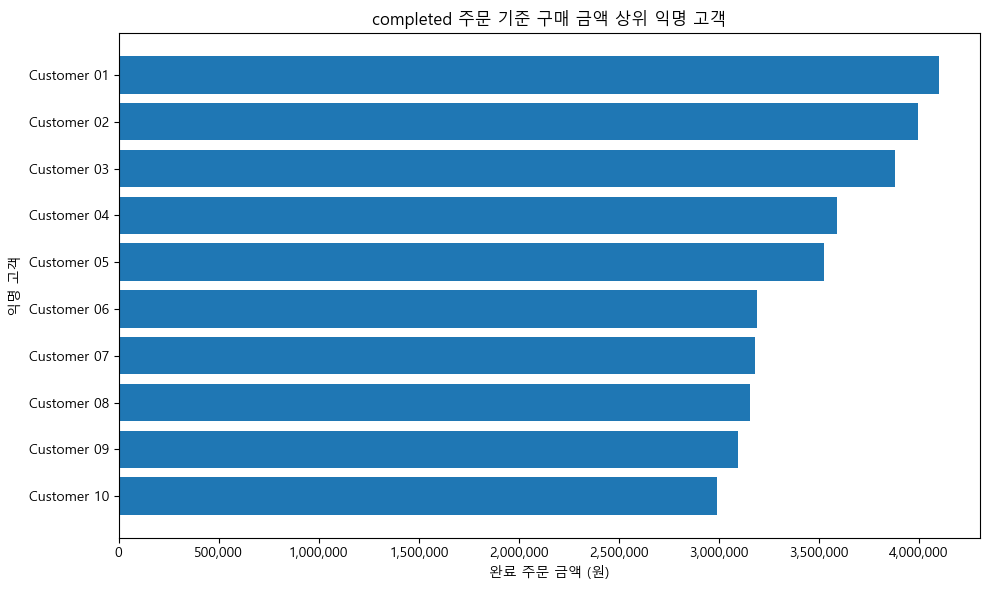

ch08_category_sales.png True 42436
ch08_monthly_sales.png True 70612
ch08_top_customers.png True 46878


In [13]:
saved_figures = create_project_figures(
    analysis_tables,
    FIGURE_DIR,
    show=True,
)

for path in saved_figures:
    print(path.name, path.exists(), path.stat().st_size)


### 그래프별 해석
1. 카테고리 막대: 범주 크기 비교에 적합하며 스포츠가 최고다. 수량·단가·원가를 함께 확인해야 하므로 수익성의 근거는 아니다.
2. 월별 선: 월 순서와 변동을 보여 주며 2025-10이 최고다. 첫·끝 월은 부분 월이고 광고 효과나 계절성을 단정할 수 없다.
3. 익명 고객 가로 막대: 상위 고객의 금액 차이를 보여 준다. 순위 라벨로 원본 ID 노출을 줄였으며 구매 의도·충성도는 말할 수 없다.
모든 그래프는 검증된 집계표를 직접 사용하고 원 단위를 표시했다. 별도 검증 스크립트에서 집계값을 대조한다.

## 14. Markdown 보고서 생성

보고서에는 계산 기준, PK/FK·병합, `line_total`, total consistency, 개인정보, 최종 Validation을 함께 남깁니다.


In [14]:
report_text = build_midterm_report(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
)

report_path = REPORT_DIR / "ch08_midterm_report.md"
report_path.write_text(report_text, encoding="utf-8")

print("보고서 저장:", report_path)
print(report_text[:1800])


보고서 저장: C:\Users\신윤철\Documents\llm-data-analysis-study\chapter08\reports\ch08_midterm_report.md
# Chapter 8 중간 프로젝트 보고서

## 1. 분석 목적

온라인 쇼핑몰 데이터를 사용해 completed 주문 기준 금액과 고객 구매 패턴을 분석했습니다.

## 2. 분석 기준

- 금액성 분석은 `order_status == "completed"`인 주문만 포함했습니다.
- `line_total = quantity × unit_price` 관계를 검증했습니다.
- 취소·환불 등 non-completed 주문을 포함한 금액은 전체 주문 상세 금액으로 구분했습니다.
- 공개 고객 결과에서는 이름·연락처·원본 고객 ID를 제외하고 순위 기반 익명 라벨을 사용했습니다.
- 병합은 관계 검증, `validate`, 행 수, 미매칭을 확인했습니다.
- 같은 completed 범위의 카테고리·월·고객 총합을 source total과 대조했습니다.

## 3. 데이터 개요

```text
    dataset  rows  columns  missing_values  duplicated_rows
  customers   150        6               0                0
   products   100        4               0                0
     orders   300        5               0                0
order_items   764        5               0                0
```

## 4. 전처리 전후 비교

```text
    dataset  rows_raw  columns_raw  rows_processed  columns_processed
  customers       150            6             150       

## 15. 전체 파이프라인 재실행

단계별 셀을 확인한 뒤에는 `run_midterm_project()`로 원본부터 보고서까지 다시 실행합니다. Notebook의 이전 메모리 상태에 의존하지 않는지 확인하는 단계입니다.


In [15]:
import os
import subprocess
env = {**os.environ, "PYTHONIOENCODING": "utf-8", "MPLBACKEND": "Agg"}
snapshots = {name: analysis_tables[name].copy(deep=True) for name in ["category_sales", "monthly_sales", "customer_sales_public", "total_consistency_check"]}
log_parts = []
for script in ["run_midterm_project.py", "verify_project.py"]:
    completed_process = subprocess.run([sys.executable, str(PROJECT_ROOT / "scripts" / script)], cwd=PROJECT_ROOT, env=env, capture_output=True, text=True, encoding="utf-8")
    log_parts.append(f"[{script}] exit code = {completed_process.returncode}\n{completed_process.stdout}\n{completed_process.stderr}")
    print(log_parts[-1])
    assert completed_process.returncode == 0, f"{script} failed"
file_map = {"category_sales": "ch08_category_sales.csv", "monthly_sales": "ch08_monthly_sales.csv", "customer_sales_public": "ch08_customer_sales.csv", "total_consistency_check": "ch08_total_consistency_check.csv"}
for name, filename in file_map.items():
    saved = pd.read_csv(REPORT_DIR / filename)
    pd.testing.assert_frame_equal(snapshots[name].reset_index(drop=True), saved.reset_index(drop=True), check_dtype=False, check_exact=False, rtol=1e-9, atol=1e-6)
(REPORT_DIR / "ch08_reproduction_log.txt").write_text("\n".join(log_parts), encoding="utf-8")
print("Notebook vs separate process: all four tables MATCH")
display(pd.read_csv(REPORT_DIR / "ch08_project_validation.csv"))

[run_midterm_project.py] exit code = 0
Chapter 08: completed

[Total consistency]
          source      amount  difference_from_completed  matches_completed status
completed_source 148990000.0                        0.0               True   PASS
        category 148990000.0                        0.0               True   PASS
         monthly 148990000.0                        0.0               True   PASS
        customer 148990000.0                        0.0               True   PASS

[Final Validation]
                                 check                value             expected status
                          pk_integrity             all PASS             all PASS   PASS
                          fk_integrity                    0                    0   PASS
                     merge_checks_pass             all PASS             all PASS   PASS
                line_total_consistency                    0                    0   PASS
           completed_total_consistency          

[verify_project.py] exit code = 0
                           check status
     raw_unchanged_customers.csv   PASS
   raw_unchanged_order_items.csv   PASS
        raw_unchanged_orders.csv   PASS
      raw_unchanged_products.csv   PASS
raw_no_missing_or_duplicate_rows   PASS
            category_all_amounts   PASS
               month_all_amounts   PASS
           monthly_unique_orders   PASS
         customer_ranked_amounts   PASS
         public_customer_columns   PASS
               rank_based_labels   PASS
                  four_way_total   PASS
    official_validation_all_pass   PASS
Independent checks: 13 PASS; completed total = 148,990,000 KRW


Notebook vs separate process: all four tables MATCH


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


## 16. 최종 산출물 검증

필수 CSV·PNG·Markdown이 존재하고 비어 있지 않은지 확인합니다.


In [16]:
expected_outputs = [
    REPORT_DIR / "ch08_midterm_report.md",
    REPORT_DIR / "ch08_dataset_summary.csv",
    REPORT_DIR / "ch08_preprocessing_comparison.csv",
    REPORT_DIR / "ch08_key_duplicate_checks.csv",
    REPORT_DIR / "ch08_relationship_checks.csv",
    REPORT_DIR / "ch08_merge_checks.csv",
    REPORT_DIR / "ch08_line_total_check.csv",
    REPORT_DIR / "ch08_date_checks.csv",
    REPORT_DIR / "ch08_amount_scope_summary.csv",
    REPORT_DIR / "ch08_total_consistency_check.csv",
    REPORT_DIR / "ch08_project_validation.csv",
    REPORT_DIR / "ch08_category_sales.csv",
    REPORT_DIR / "ch08_monthly_sales.csv",
    REPORT_DIR / "ch08_customer_sales.csv",
    REPORT_DIR / "ch08_order_status_summary.csv",
    REPORT_DIR / "ch08_interpretation_notes.csv",
    FIGURE_DIR / "ch08_category_sales.png",
    FIGURE_DIR / "ch08_monthly_sales.png",
    FIGURE_DIR / "ch08_top_customers.png",
]

all_outputs_valid = True
for path in expected_outputs:
    valid = path.exists() and path.stat().st_size > 0
    all_outputs_valid &= valid
    print(path.name, "OK" if valid else "MISSING OR EMPTY")

assert all_outputs_valid
print("전체 산출물 검증: PASS")


ch08_midterm_report.md OK
ch08_dataset_summary.csv OK
ch08_preprocessing_comparison.csv OK
ch08_key_duplicate_checks.csv OK
ch08_relationship_checks.csv OK
ch08_merge_checks.csv OK
ch08_line_total_check.csv OK
ch08_date_checks.csv OK
ch08_amount_scope_summary.csv OK
ch08_total_consistency_check.csv OK
ch08_project_validation.csv OK
ch08_category_sales.csv OK
ch08_monthly_sales.csv OK
ch08_customer_sales.csv OK
ch08_order_status_summary.csv OK
ch08_interpretation_notes.csv OK
ch08_category_sales.png OK
ch08_monthly_sales.png OK
ch08_top_customers.png OK
전체 산출물 검증: PASS


## 17. LLM 검토 프롬프트 예시

원본 고객 행이나 직접 식별정보 대신 비식별 검증 Evidence를 제공합니다.

```text
온라인 쇼핑몰 중간 프로젝트 결과를 검토해 주세요.

계산 기준:
- line_total = quantity × unit_price
- 금액성 분석은 order_status == completed만 사용

검증 결과:
- PK 결측/중복: 0
- FK 미매칭: 0
- merge checks: PASS
- category/month/customer totals: source total과 일치
- completed 주문 날짜 오류: 0
- 공개 고객 CSV에 원본 customer_id 없음

다음을 검토해 주세요.
1. 아직 확인하지 않은 분석 위험
2. 과도한 해석이 될 수 있는 표현
3. 보고서에 반드시 적어야 할 계산 기준
4. 추가로 필요한 검증
5. 데이터에 없는 원인은 추정하지 않기
```

LLM은 검토 범위를 넓히는 도구이지 프로젝트의 최종 승인자가 아닙니다.


## 18. 실습 과제

1. 핵심 EDA 결과 3개를 선택하고 각각 근거와 한계를 작성합니다.
2. 대표 그래프 2~4개를 선택하고 원본 집계값과 일치하는지 확인합니다.
3. `ch08_total_consistency_check.csv`와 `ch08_project_validation.csv`를 확인합니다.
4. 공개 고객 CSV에 개인정보가 없는지 다시 확인합니다.
5. LLM을 사용했다면 목적·Prompt 요약·제안·반영 여부·사람의 검증 근거를 기록합니다.
6. `python scripts/run_midterm_project.py`로 전체 프로젝트를 다시 실행하고 Notebook의 핵심 수치와 비교합니다.


In [17]:
# 18. 실습 과제 완료 확인: 공개 결과·최종 검증·재현 근거
display(pd.read_csv(REPORT_DIR / "ch08_independent_checks.csv"))
print("원본·카테고리·월·고객 독립 재계산: PASS")
print("상세 답안은 아래 제출 답안 Markdown에 작성했다.")

,check,status
0,raw_unchanged_customers.csv,PASS
1,raw_unchanged_order_items.csv,PASS
2,raw_unchanged_orders.csv,PASS
3,raw_unchanged_products.csv,PASS
4,raw_no_missing_or_duplicate_rows,PASS
5,category_all_amounts,PASS
6,month_all_amounts,PASS
7,monthly_unique_orders,PASS
8,customer_ranked_amounts,PASS
9,public_customer_columns,PASS


원본·카테고리·월·고객 독립 재계산: PASS
상세 답안은 아래 제출 답안 Markdown에 작성했다.


## 정리

이번 장에서는 원본 데이터 확인, 전처리, PK/FK, 병합, `line_total`, completed 범위, total consistency, 날짜, 개인정보, 시각화, 보고서, 최종 Validation을 하나의 프로젝트로 연결했습니다.

기억할 핵심은 다음과 같습니다.

```text
실행 성공 ≠ 검증 완료
같은 의미의 숫자는 서로 다른 집계에서도 같아야 한다
공개 결과에는 불필요한 개인정보를 남기지 않는다
프로젝트는 원본부터 다시 실행할 수 있어야 한다
```


# 제출 답안: Chapter 08 작은 데이터 분석 프로젝트

## 제출 정보
- 이름: 신윤철
- GitHub ID: ycshin2002
- 작성일: 2026-11-04
- 최종 Notebook URL: https://github.com/ycshin2002/llm-data-analysis-study/blob/main/chapter08/chapter08.ipynb

## 1. 프로젝트 질문
### 분석 질문
1. 카테고리별 completed 주문 금액과 비중은 어떻게 다른가?
2. 월별 completed 주문 금액과 고유 주문 수는 어떻게 변하는가?
3. completed 구매 금액 상위 익명 고객은 구매 횟수와 주문당 금액에서 어떤 특징을 보이는가?
### 분석 범위
공식 공개 저장소의 가상 쇼핑몰 원본 4개 파일을 사용한다. 전체 주문의 관측 날짜는 2025-07-09~2026-07-08이다. 금액·고객 분석은 completed 주문만 포함하고, 주문 상태 분포만 전체 orders를 사용한다. 금액은 원 단위이며 회계상 순매출이나 이익을 뜻하지 않는다.
### 사용할 데이터와 지표
customers, products, orders, order_items를 사용한다. 금액 합계, 금액 비중, 고유 주문 수, 고객별 주문당 평균 금액을 계산한다. 주문 수는 상세 행 수가 아니라 order_id.nunique()이다.
### 계산 기준
- `order_status == "completed"`: 적용함(184개 주문, 474개 상세 행).
- `line_total = quantity × unit_price`: 764개 상세 행에서 검증, 불일치 0건.
### 완료 기준
PK 결측·중복 0, FK 미매칭 0, 병합 행 수 보존, 계산 불일치 0, 날짜 오류 0, 네 금액 총합 일치, 공개 고객 결과 금지 컬럼 없음, 최종 Validation 8개 PASS 및 별도 재실행 결과 일치를 완료 기준으로 삼았다.

## 2. 입력 데이터와 전처리 검증
- 원본: `data/raw/customers.csv`, `products.csv`, `orders.csv`, `order_items.csv`.
- shape: 고객 (150, 6), 상품 (100, 4), 주문 (300, 5), 상세 (764, 5).
- 결측·완전 중복: 4개 원본 파일 모두 0건.
- 전처리 전후 행 수: 고객 150→150, 상품 100→100, 주문 300→300, 상세 764→764.
- 주문 열은 월·요일 파생 변수로 5→7개, 상세 열은 line_total 생성으로 5→6개가 됐다. 숫자·날짜형 변환과 문자열 앞뒤 공백 정리를 적용했다. 행 삭제·결측 대체는 이번 원본에서는 발생하지 않았다.

입력 검증 표는 본문 **3. 원본 데이터 확인 / 4. 원본을 보존하며 전처리** 출력에 있다. 직접 캡처한다면 `images/step02_data_validation.png`로 저장한다.
### 나의 해석과 판단
이번 원본은 기본 결측·중복이 없으므로 불필요한 행 삭제를 하지 않았다. 전처리 코드를 실행했다는 사실과 실제로 행이 변했다는 사실을 구분했다. 원본 파일 SHA-256도 별도 재검증했다.
### 한계와 추가 확인 사항
학습용 가상 데이터이므로 실제 쇼핑몰의 대표성을 보장하지 않는다. 이전 Chapter 05의 오염된 샘플이 아닌 최신 공식 data/raw를 사용했으므로 과거 챕터의 숫자와 직접 비교하지 않는다. 구조 검증 PASS가 현실의 기록 정확성까지 보장하지 않는다.

## 3. PK/FK·병합 검증
### PK 결과
customer_id, product_id, order_id, order_item_id의 결측·중복은 각각 0건이고 4개 모두 PASS다.
### FK 결과
orders→customers, order_items→orders, order_items→products의 미매칭은 각각 0건이고 모두 PASS다.
### 병합 결과
| 관계 | validate | 병합 전→후 | 미매칭 | 결과 |
| --- | --- | --- | --- | --- |
| 상세→주문 | many_to_one | 764→764 | 0 | PASS |
| completed 상세→상품 | many_to_one | 474→474 | 0 | PASS |
| 고객 집계→고객 | one_to_one | 100→100 | 0 | PASS |
### 나의 해석과 판단
키 중복으로 행이 늘어나거나 연결 누락으로 금액이 사라지는 문제가 없는지 확인했다. left merge의 실행 성공만으로 안전하다고 판단하지 않았다.

## 4. 핵심 EDA 결과
### 결과 1: 카테고리별 금액
- 수치/표: `ch08_category_sales.csv`. 스포츠 31,743,000원, 전체의 21.31%로 1위다.
- 결과 관찰: 최하위 패션은 10,587,000원(7.11%)이며 범주별 금액 차이가 있다.
- 나의 해석과 판단: 스포츠의 완료 주문 금액 기여가 가장 높다. 고객 선호나 이익이 가장 높다고 해석하지 않는다.
- 업무·분석적 의미: 판매 수량과 가중평균 단가를 분리해서 조사할 우선 후보로 삼을 수 있다.
- 한계: 원가·마진·노출량·재고가 없어 수익성이나 판매 효율을 평가할 수 없다.
### 결과 2: 월별 금액과 주문 수
- 수치/표: `ch08_monthly_sales.csv`. 2025-10 25,766,000원, 26개 고유 주문으로 금액 1위다. 주문당 평균 금액은 991,000원이다.
- 결과 관찰: 2026-07은 2,188,000원·2개 주문이다. 관측 종료일이 7월 8일이어서 완전한 한 달이 아니다.
- 나의 해석과 판단: 2025-10은 높은 주문 수와 주문당 금액이 함께 관측된다. 마지막 달의 낮은 금액을 하락 추세로 단정하지 않는다.
- 업무·분석적 의미: 완전한 월끼리 주문 수와 주문당 금액을 분해해 비교한다.
- 한계: 시작 월도 부분 월이며, 1년 정도의 가상 데이터만으로 계절성이나 광고 효과를 말할 수 없다.
### 결과 3: 익명 고객별 구매 금액
- 수치/표: `ch08_customer_sales.csv`. Customer 01은 4,100,000원·5회 구매, 주문당 820,000원이다. 구매 고객은 100명, 상위 10명의 금액 비중은 23.29%다.
- 결과 관찰: 금액이 높은 고객도 주문 횟수와 주문당 금액은 서로 다르다.
- 나의 해석과 판단: 고액 구매와 반복 구매를 구분해야 하며 순위가 곧 충성도를 뜻하지 않는다.
- 업무·분석적 의미: 최근 구매일·반복 구매 간격을 추가로 분석할 수 있다.
- 한계: 비구매 고객, 관측 기간 외 구매, 고객의 만족도·이탈 의도는 이 집계로 알 수 없다. 순위 기반 라벨은 직접 식별자를 줄이는 조치이지 엄밀한 재식별 불가능성을 보장하지 않는다.

## 5. Total consistency와 날짜 검증
- completed source total: 148,990,000원.
- category total: 148,990,000원.
- monthly total: 148,990,000원.
- customer total: 148,990,000원.
- 총합 일치: 네 값 모두 일치, 차이 0원.
- completed 상세의 날짜 오류 0건, 영향 금액 0원.
- 전체 상세 금액은 255,610,000원이며 completed 금액과 다르다. 취소·환불 포함분 106,620,000원을 완료 금액과 혼용하지 않았다.
### 불일치가 있었다면 원인
이번 실행에서는 불일치가 없었다. 날짜를 임의로 채우거나 오류를 제외해 PASS를 만들지 않았으며 기존 공식 Gate를 유지했다.

## 6. 대표 시각화
![대표 그래프 1](images/graph01.png)
![대표 그래프 2](images/graph02.png)
### 그래프 선택 이유
카테고리 막대그래프는 범주별 크기 비교에, 월별 선그래프는 시간 순 변화 확인에 적합하다. 익명 고객 가로 막대그래프도 본문에 추가했다.
### 그래프와 원본 집계값 일치 여부
검증된 category_sales·monthly_sales에서 직접 그렸으며 독립 재계산으로 각 카테고리·월의 금액과 고유 주문 수를 전부 대조했다. 금액 단위는 원이고 0 기준선을 사용한다.
### 그래프에서 직접 관찰한 사실
스포츠 카테고리와 2025-10의 금액이 각각 가장 높다. 그래프 아래 본문에도 관찰·해석·한계를 분리했다.
### 그래프만으로 말할 수 없는 것
광고 효과·프로모션·고객 선호·수익성·미래 성과는 설명할 수 없다. 부분 월의 높낮이는 기간 차이를 함께 고려해야 한다.

## 7. 개인정보 검증
- 공개 고객 CSV 컬럼: customer_label, city, order_count, total_sales, avg_order_value.
- 원본 customer_id 및 name/email/phone/address: 공개 집계 CSV·고객 그래프에 없음.
- 익명 라벨: 구매 금액 순위 기반 Customer 01, Customer 02 등(원본 ID를 붙이지 않음).
- 저장된 공개 CSV를 다시 읽어 금지 컬럼 없음 확인: PASS.
### 나의 판단
제공된 원본은 가상 쇼핑몰 실습 데이터이고 실제 개인정보가 아니다. 입력의 가상 ID와 이름은 계산용 원본으로 보존하되, 노트북 출력·보고서·공개 고객 결과에는 원본 고객 행이나 ID-라벨 대응표를 출력하지 않았다. 실제 데이터라면 원본을 공개 저장소에 넣어서는 안 된다.

## 8. 최종 Validation
| 검증 항목 | 결과 | 내가 확인한 근거 |
| --- | --- | --- |
| pk_integrity | PASS | PK 결측·중복 모두 0 |
| fk_integrity | PASS | 3개 관계 미매칭 0 |
| merge_checks_pass | PASS | 관계 통과·행 수 보존·미매칭 0 |
| line_total_consistency | PASS | 764개 상세 불일치 0 |
| completed_total_consistency | PASS | 네 총합 148,990,000원, 차이 0 |
| category_sales_ratio_pct_sum | PASS | 비중 합 100.00% |
| completed_rows_with_invalid_order_date | PASS | 날짜 오류 0 |
| public_customer_columns_safe | PASS | 저장 공개 CSV 금지 컬럼 없음 |
### FAIL이 있었다면 수정 내용
공식 원본과 공식 계산 기준으로 1차 실행부터 모두 PASS였다. 필터·Gate·기대값을 약화하거나 원본 숫자를 수정하지 않았다. 로컬 편의 변경은 경로 탐색, 스크립트 실행 경로, 그래프 축 단위·0 기준선, 추가 검증과 해석 셀이다.

## 9. LLM 활용 기록
- 사용 여부/목적: AI로 코드 구성, 경로 보완, 검증 코드 및 해석 초안을 작성했다.
- Safe Context: 공식 코드·스키마·비식별 요약 통계·검증표를 사용했고 원본 고객 행·이름·ID-라벨 대응표는 제시하지 않았다.
- Prompt 요약: 공식 Chapter 08과 LMS 요구에 맞게 실행 노트북·산출물을 작성하고 수치·키·개인정보·재현성을 검증하도록 요청했다.
- 제안/반영: completed 범위 통일, PK/FK Gate, 총합 대조, 순위 라벨, 별도 프로세스 재실행을 반영했다.
- 수정/보류: 과거 챕터의 금액을 재사용하지 않고 현재 원본에서 계산했다. 마케팅·선호·충성도에 대한 인과 해석은 제외했다.
- 검증 근거: 실제 실행한 공식 Validation 8개와 독립 재계산 CSV, 별도 프로세스 출력 로그가 있다. 자동 실행·검증은 AI가 수행했으며 제출자의 수동 검토·캡처·GitHub 표시 확인은 제출 전에 별도로 수행해야 한다. 사람이 이미 검수했다고 기재하지 않았다.

## 10. 프로젝트 재현 확인
- chapter08 폴더를 기준으로 `python scripts/run_midterm_project.py` 실행: Notebook **15. 전체 파이프라인 재실행**에서 동일 Python의 별도 프로세스로 실행함.
- 결과: 종료 코드 0, 공식 Validation 8개 PASS.
- Notebook과 재실행 CSV: 핵심 집계표 전부 대조, 값 일치.
- 독립 검증: `python scripts/verify_project.py`로 원본 해시, 카테고리·월·고객 금액, 월별 고유 주문 수, 공개 컬럼·라벨을 별도 계산으로 확인했다.
- 생성 파일: 공식 19개 CSV·PNG·Markdown이 모두 존재하고 비어 있지 않음.

재실행 화면은 본문 **15. 전체 파이프라인 재실행** 출력에 있다. 직접 캡처한다면 `images/step06_reproduce.png`로 저장한다.
### 나의 해석과 판단
같은 커널에서 셀을 재실행하는 것과 별도 프로세스에서 원본부터 계산하는 것을 구분했다. 재현성은 메모리에 남은 이전 변수에 기대지 않고 같은 입력과 기준으로 같은 결과를 얻는 성질이다.

## 11. 최종 프로젝트 요약
### 핵심 인사이트 3개
1. 스포츠의 완료 금액은 31,743,000원(21.31%)으로 가장 높다. 수량·단가를 추가로 분해할 우선 후보이며, 수익성이 가장 높다는 뜻은 아니다.
2. 2025-10의 25,766,000원·26개 주문은 월별 금액 최고점이다. 주문 수와 주문당 금액을 함께 봐야 하며, 부분 월이나 광고 원인과 혼동하지 않아야 한다.
3. 상위 10명은 완료 금액의 23.29%를 차지한다. 반복 구매와 고액 일회성 구매를 구분할 가치가 있으나, 미래 충성도나 이탈을 예측할 근거는 아니다.
### 가장 중요한 업무·분석적 의미
어떤 범주·기간·고객에 금액이 모였는지를 같은 기준으로 확인하고, 원인 검증이 필요한 다음 질문을 정할 수 있다.
### 현재 분석의 한계
가상 데이터, 짧고 부분 월을 포함한 관측 기간, 원가·광고·재고·노출량 부재가 한계다. PASS는 정의한 구조·수치 검증의 통과이지 현실 타당성이나 인과관계의 증명이 아니다.
### 다음 분석 제안
1. 카테고리 금액을 판매 수량과 가중평균 판매 단가로 분해한다.
2. 완전한 월만 골라 주문 수와 주문당 평균 금액을 비교한다.
3. 최근 구매일·반복 간격을 포함해 고액 구매와 반복 구매를 구분한다.

## 최종 체크
- [x] 질문·범위·지표를 정의하고 원본부터 다시 실행했다.
- [x] PK/FK·병합·금액·날짜·공개 컬럼을 검증했다.
- [x] 카테고리/월/고객 총합이 source와 일치한다.
- [x] 그래프와 집계값을 대조하고 관찰·해석·한계를 구분했다.
- [x] 공식 Validation 8개 PASS, 독립 재계산 및 별도 프로세스 재실행을 확인했다.
- [ ] 제출자 수동 검토 및 필요한 화면 캡처를 완료했다.
- [ ] GitHub에서 최종 Notebook 표시를 확인하고 파일 URL을 LMS에 제출했다.

## 캡처한 증빙 이미지 확인 (선택)
입력 검증과 재실행 화면을 저장한 뒤 아래 셀을 재실행하면 디스크의 최신 이미지를 직접 읽는다. 커널 재시작이나 이미지 동기화 스크립트는 필요 없다.

In [18]:
from IPython.display import Image, display
for name in ["step02_data_validation.png", "step06_reproduce.png"]:
    path = PROJECT_ROOT / "images" / name
    if path.exists():
        print(name)
        display(Image(data=path.read_bytes(), width=1000))
    else:
        print(f"선택 캡처 대기: images/{name} (기존 실행 출력은 위 본문에 보존됨)")

선택 캡처 대기: images/step02_data_validation.png (기존 실행 출력은 위 본문에 보존됨)
선택 캡처 대기: images/step06_reproduce.png (기존 실행 출력은 위 본문에 보존됨)
